In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from tqdm import tqdm

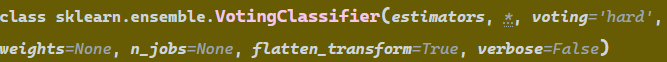

In [4]:
df = pd.read_csv("../Day5/BreastCancer.csv",index_col=0)
df.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [5]:
X, y = df.drop("Class",axis=1), df["Class"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3,stratify=y)

In [7]:
dtc = DecisionTreeClassifier(random_state=26)
lr = LogisticRegression()
knn = KNeighborsClassifier()
voting = VotingClassifier([("TREE",dtc),("LR",lr),("KNN",knn)])
voting.fit(X_train,y_train)
y_pred = voting.predict(X_test)
accuracy_score(y_test,y_pred)

0.9571428571428572

In [13]:
voting.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('TREE', ...), ('LR', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](2,)","['Benign','Malignant']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[DecisionTreeC...ndom_state=26), LogisticRegression(), KNeighborsClassifier()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Clump','UniCell_Size','Uni_CellShape',...,'BChromatin','NoemN','Mitoses']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [15]:
depths = [None,2,3,4,5]
solvers = ['lbfgs','saga','sag','liblinear']
Ks = [2,5,10]
scores = []
for d in tqdm(depths):
    for s in solvers:
        for k in Ks:
            dtc = DecisionTreeClassifier(random_state=26, max_depth=d)
            lr = LogisticRegression(solver=s)
            knn = KNeighborsClassifier(n_neighbors=k)
            voting = VotingClassifier([("TREE",dtc),("LR",lr),("KNN",knn)])
            voting.fit(X_train,y_train)
            y_pred = voting.predict(X_test)
            scores.append([d,s,k,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["D","S","K","Scores"])
df_scores.sort_values("Scores",ascending=False)

  0%|                                                                                            | 0/5 [00:00<?, ?it/s]C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roami

,D,S,K,Scores
38,4.0,lbfgs,10,0.966667
2,NaN,lbfgs,10,0.966667
14,2.0,lbfgs,10,0.966667
26,3.0,lbfgs,10,0.966667
50,5.0,lbfgs,10,0.966667
27,3.0,saga,2,0.961905
20,2.0,sag,10,0.961905
21,2.0,liblinear,2,0.961905
23,2.0,liblinear,10,0.961905
47,4.0,liblinear,10,0.961905


In [18]:
dtc = DecisionTreeClassifier(random_state=26)
lr = LogisticRegression()
knn = KNeighborsClassifier()
voting = VotingClassifier([("TREE",dtc),("LR",lr),("KNN",knn)],voting="soft")
voting.fit(X_train,y_train)
y_pred = voting.predict(X_test)
accuracy_score(y_test,y_pred)

0.9571428571428572

In [17]:
depths = [None,2,3,4,5]
solvers = ['lbfgs','saga','sag','liblinear']
Ks = [2,5,10]
scores = []
for d in tqdm(depths):
    for s in solvers:
        for k in Ks:
            dtc = DecisionTreeClassifier(random_state=26, max_depth=d)
            lr = LogisticRegression(solver=s)
            knn = KNeighborsClassifier(n_neighbors=k)
            voting = VotingClassifier([("TREE",dtc),("LR",lr),("KNN",knn)],voting="soft")
            voting.fit(X_train,y_train)
            y_pred = voting.predict(X_test)
            scores.append([d,s,k,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["D","S","K","Scores"])
df_scores.sort_values("Scores",ascending=False)

  0%|                                                                                            | 0/5 [00:00<?, ?it/s]C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Roami

,D,S,K,Scores
30,3.0,sag,2,0.971429
45,4.0,liblinear,2,0.971429
33,3.0,liblinear,2,0.971429
27,3.0,saga,2,0.971429
24,3.0,lbfgs,2,0.971429
36,4.0,lbfgs,2,0.971429
39,4.0,saga,2,0.971429
42,4.0,sag,2,0.971429
21,2.0,liblinear,2,0.966667
18,2.0,sag,2,0.966667


## Evaluated individual Estimators

In [19]:
voting.named_estimators_

{'TREE': DecisionTreeClassifier(random_state=26),
 'LR': LogisticRegression(),
 'KNN': KNeighborsClassifier()}

In [23]:
y_test_enc = np.where(y_test=="Malignant",1,0)
y_pred = voting.named_estimators_["TREE"].predict(X_test)
print("Tree Acc : ",accuracy_score(y_test_enc,y_pred))

Tree Acc :  0.9476190476190476


In [24]:
y_test_enc = np.where(y_test=="Malignant",1,0)
y_pred = voting.named_estimators_["LR"].predict(X_test)
print("LR Acc : ",accuracy_score(y_test_enc,y_pred))

LR Acc :  0.9619047619047619


In [25]:
y_test_enc = np.where(y_test=="Malignant",1,0)
y_pred = voting.named_estimators_["KNN"].predict(X_test)
print("KNN Acc : ",accuracy_score(y_test_enc,y_pred))

KNN Acc :  0.9619047619047619
